# PM2.5 AQI — Reproducible Research Results

This notebook **displays and verifies archived, fixed internal-holdout results**. It does not fit models, inspect protected holdout labels, conduct a new search or overwrite scientific results. The source CSV is not needed to inspect the archived report. For development-only retraining, follow [`docs/REPRODUCIBILITY.md`](docs/REPRODUCIBILITY.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from scripts.verify_release import verify
ROOT = Path.cwd().resolve()
assert (ROOT / "LOCKED_PROTOCOL.json").is_file(), "Start Jupyter from repository root"
status = verify(ROOT)
print("Archived release verified (no training or holdout re-evaluation):")
print(json.dumps(status, indent=2))

Archived release verified (no training or holdout re-evaluation):
{
  "receipt_files_verified": 11,
  "holdout_rows_archived": 4707,
  "dataset_available": false,
  "dataset_expected_sha256": "e1fc6e682edb8a2102d87e182b844fc8cde49e10763c0ef4293e510bbe240f69"
}


## Frozen internal-holdout results

The primary regressors/classifiers were designated before the one-shot holdout assessment. A comparator scoring better here **does not** become a newly selected model. This is internal same-dataset evaluation, not external validation.

In [2]:
base = ROOT / "results" / "batch"
regression = pd.read_csv(base / "final_regression_fixed.csv")
classification = pd.read_csv(base / "final_classification_fixed.csv")
print("Regression — MAE in original AQI points (lower is better)")
display(regression.round(4))
print("Six-class classification — macro-F1, accuracy and balanced accuracy")
display(classification.round(4))

Regression — MAE in original AQI points (lower is better)


,model,n,mae,rmse,r2
0,log_hgb_A5,4707,16.9370,29.6646,0.6900
1,log_hgb_A4,4707,16.9750,29.5531,0.6923
2,huber_stack,4707,16.8725,29.0372,0.7029


Six-class classification — macro-F1, accuracy and balanced accuracy


,model,n,macro_f1,weighted_f1,balanced_accuracy,accuracy,ordinal_mae,quadratic_kappa
0,lightgbm_A4,4707,0.4977,0.6914,0.4829,0.7038,0.3397,0.7818
1,rf_balanced_A4,4707,0.5537,0.6896,0.5966,0.6892,0.3535,0.7896
2,hgb_A5_to_class,4707,0.4609,0.6854,0.4541,0.6926,0.3369,0.7894


## Prespecified uncertainty and diagnostics

Bootstrap intervals describe the fixed fitted models on this source and split. They do **not** incorporate all past model searches, cross-country dependence or external validity.

In [3]:
for title, filename in [
    ("Paired contrasts", "final_paired_pattern_CIs.csv"),
    ("Per-category outcomes", "final_six_class_metrics.csv"),
    ("Country-held-out development sensitivity", "country_transfer_fixed_models.csv"),
]:
    print(title)
    display(pd.read_csv(base / filename).round(4).head(20))

Paired contrasts


,task,a,b,metric,point_estimate,ci_low,ci_high
0,regression,log_hgb_A5,log_hgb_A4,MAE(a)-MAE(b),-0.0380,-0.1545,0.0731
1,regression,huber_stack,log_hgb_A5,MAE(a)-MAE(b),-0.0645,-0.2476,0.1059
2,classification,lightgbm_A4,rf_balanced_A4,Macro-F1(a)-Macro-F1(b),-0.0560,-0.0950,-0.0185
3,classification,lightgbm_A4,hgb_A5_to_class,Macro-F1(a)-Macro-F1(b),0.0368,-0.0044,0.0736
4,safety,lightgbm_A4,rf_balanced_A4,Hazardous recall(a)-recall(b),-0.2414,-0.4033,-0.0968


Per-category outcomes


,model,category,support,precision,recall,f1
0,lightgbm_A4,Good,1998,0.7382,0.8328,0.7827
1,lightgbm_A4,Moderate,1880,0.6944,0.6670,0.6804
2,lightgbm_A4,Unhealthy for Sensitive Groups,330,0.5211,0.2242,0.3136
3,lightgbm_A4,Unhealthy,420,0.6538,0.7286,0.6892
4,lightgbm_A4,Very Unhealthy,50,0.5556,0.1000,0.1695
5,lightgbm_A4,Hazardous,29,0.3571,0.3448,0.3509
6,rf_balanced_A4,Good,1998,0.7409,0.8258,0.7811
7,rf_balanced_A4,Moderate,1880,0.7180,0.6122,0.6609
8,rf_balanced_A4,Unhealthy for Sensitive Groups,330,0.3771,0.4697,0.4184
9,rf_balanced_A4,Unhealthy,420,0.7278,0.5857,0.6491


Country-held-out development sensitivity


,model,fold,n_validation,mae,rmse,r2,macro_f1,weighted_f1,balanced_accuracy,accuracy,ordinal_mae,quadratic_kappa
0,log_hgb_A5,1,6871,32.8552,61.6042,0.1592,NaN,NaN,NaN,NaN,NaN,NaN
1,lightgbm_A4,1,6871,NaN,NaN,NaN,0.3070,0.4826,0.2946,0.4967,0.6944,0.4168
2,rf_balanced_A4,1,6871,NaN,NaN,NaN,0.3059,0.4489,0.3043,0.4494,0.7353,0.4598
3,log_hgb_A5,2,1723,28.2824,45.6929,0.2654,NaN,NaN,NaN,NaN,NaN,NaN
4,lightgbm_A4,2,1723,NaN,NaN,NaN,0.2901,0.5270,0.2939,0.5572,0.5862,0.4911
5,rf_balanced_A4,2,1723,NaN,NaN,NaN,0.2850,0.5017,0.2977,0.5305,0.6053,0.5079
6,log_hgb_A5,3,5518,18.9096,25.3162,0.3333,NaN,NaN,NaN,NaN,NaN,NaN
7,lightgbm_A4,3,5518,NaN,NaN,NaN,0.4207,0.6118,0.3922,0.6109,0.4087,0.4703
8,rf_balanced_A4,3,5518,NaN,NaN,NaN,0.4248,0.6439,0.4117,0.6618,0.3693,0.5103


## Figures from the archived experiment

These are publication-oriented visual summaries of the precommitted comparisons; no test results are recomputed.

FINAL_fixed_models.png


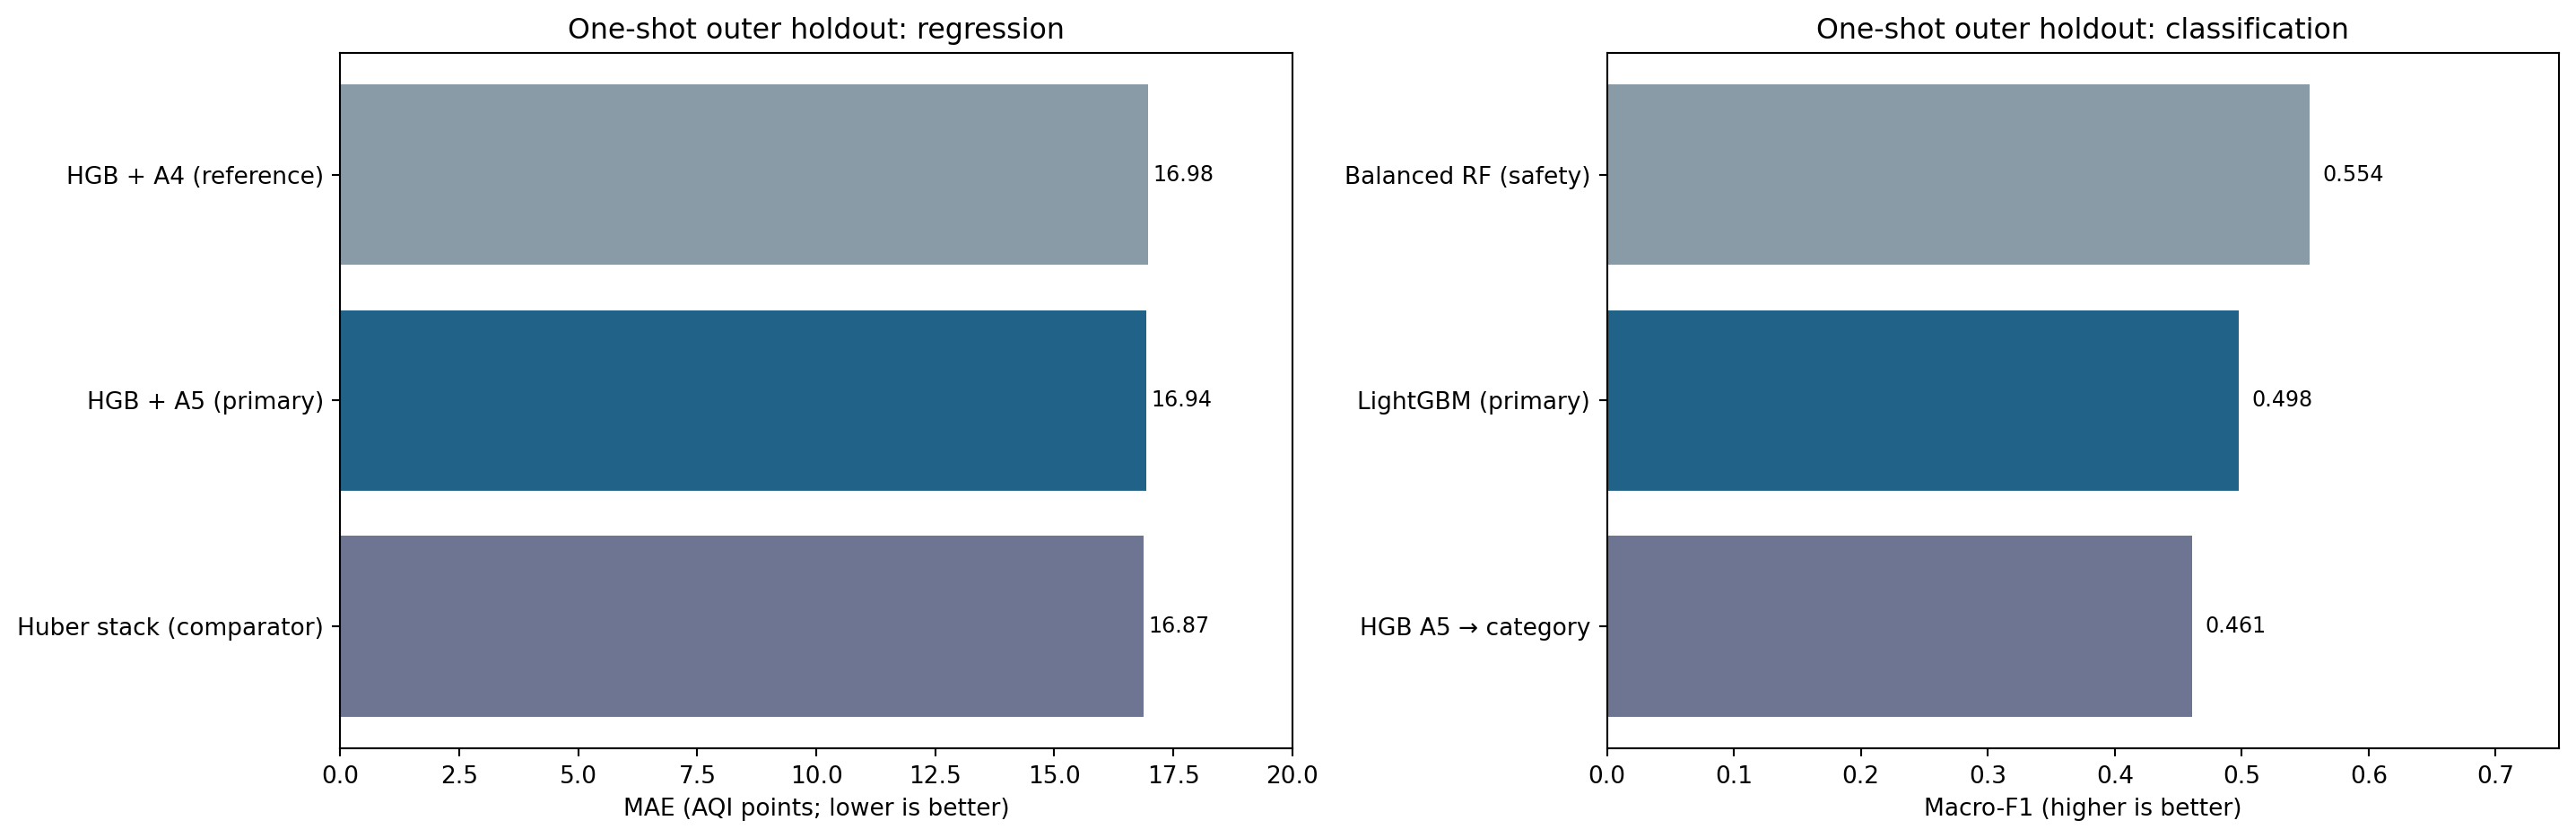

FINAL_confusion_matrices.png


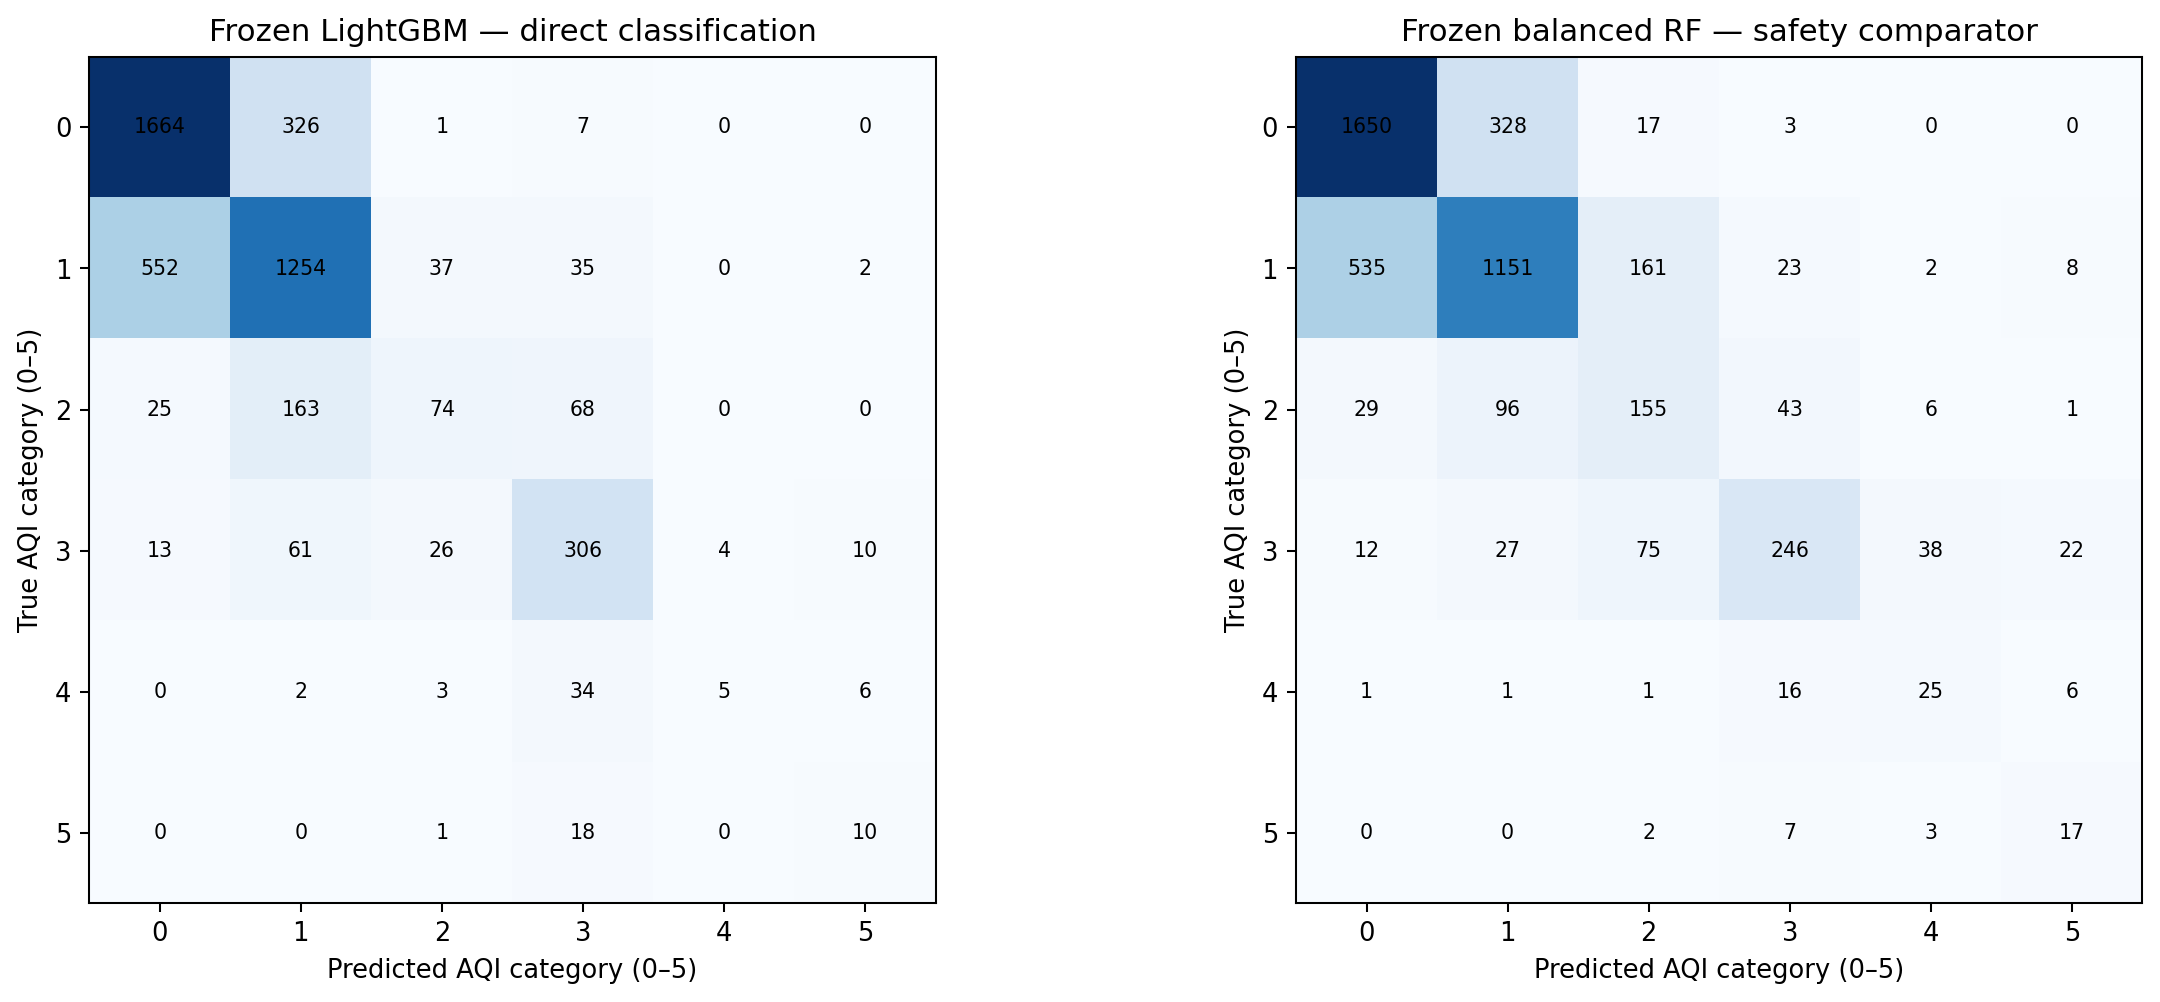

FINAL_per_category_recall.png


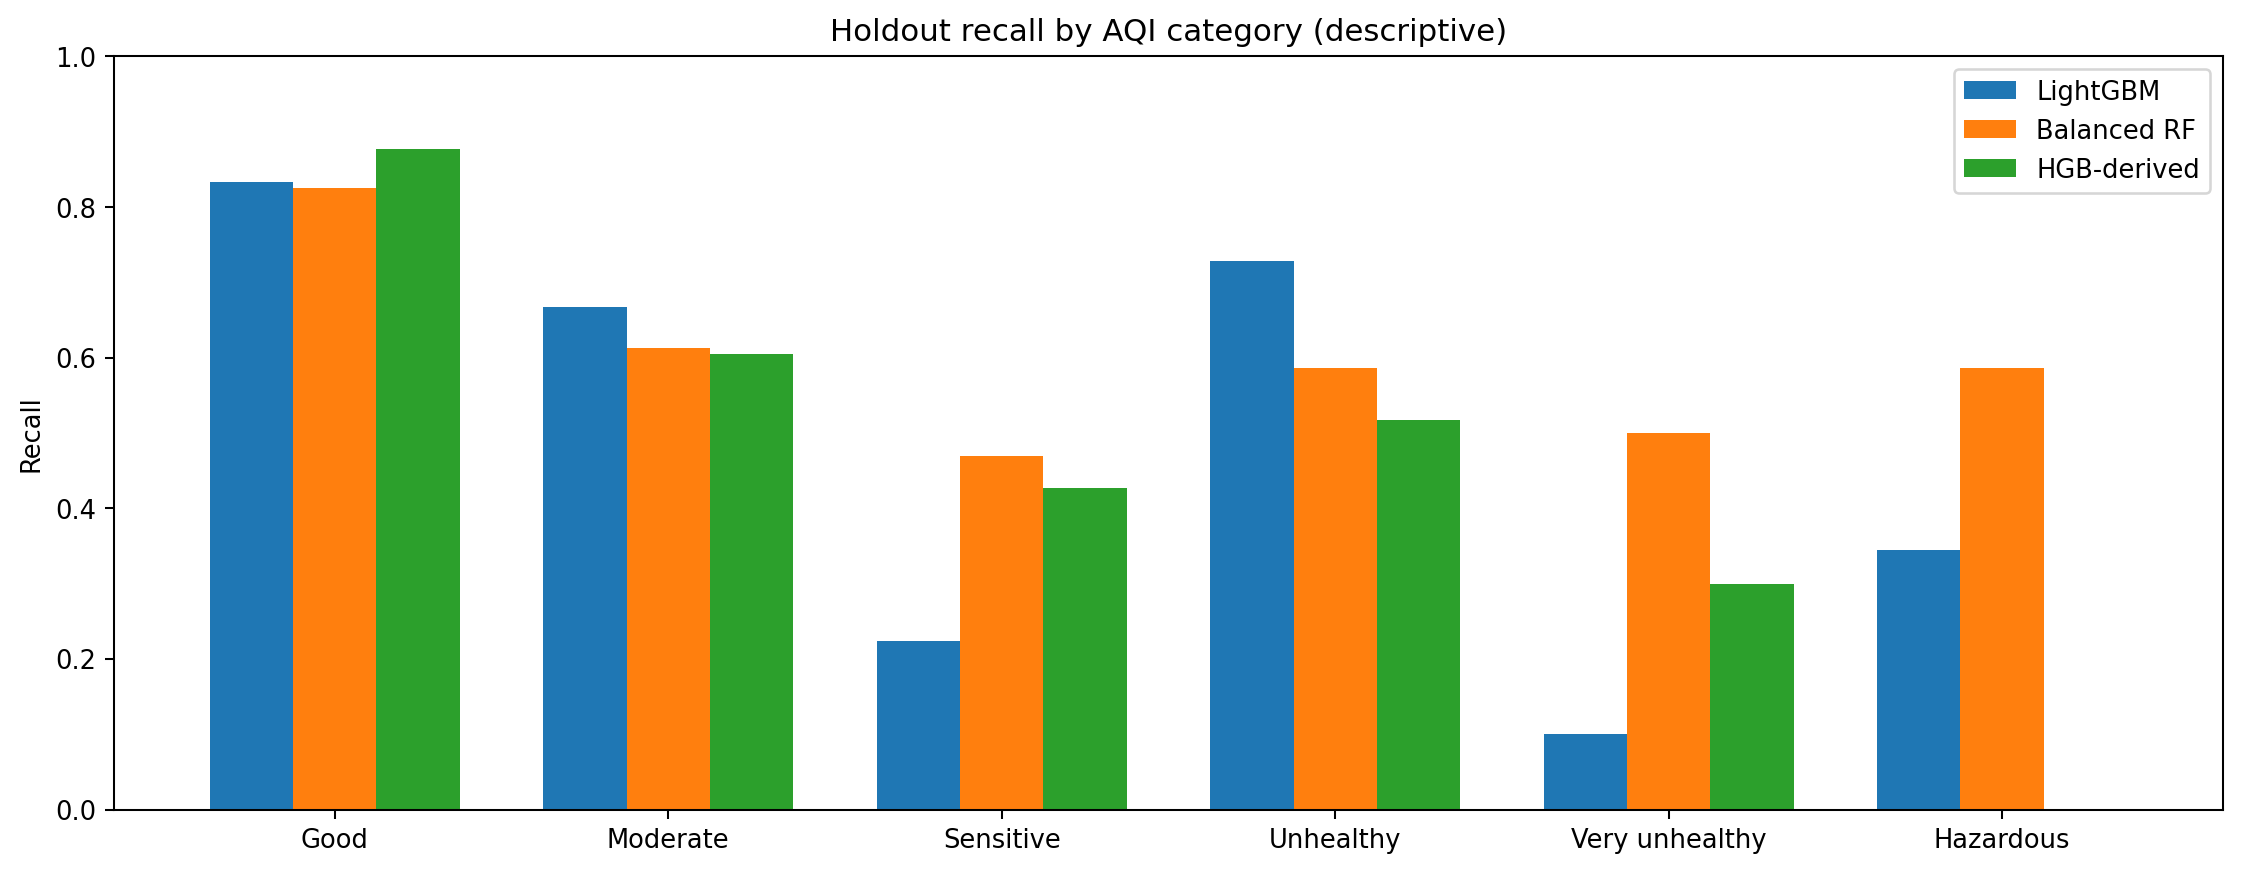

FINAL_calibration.png


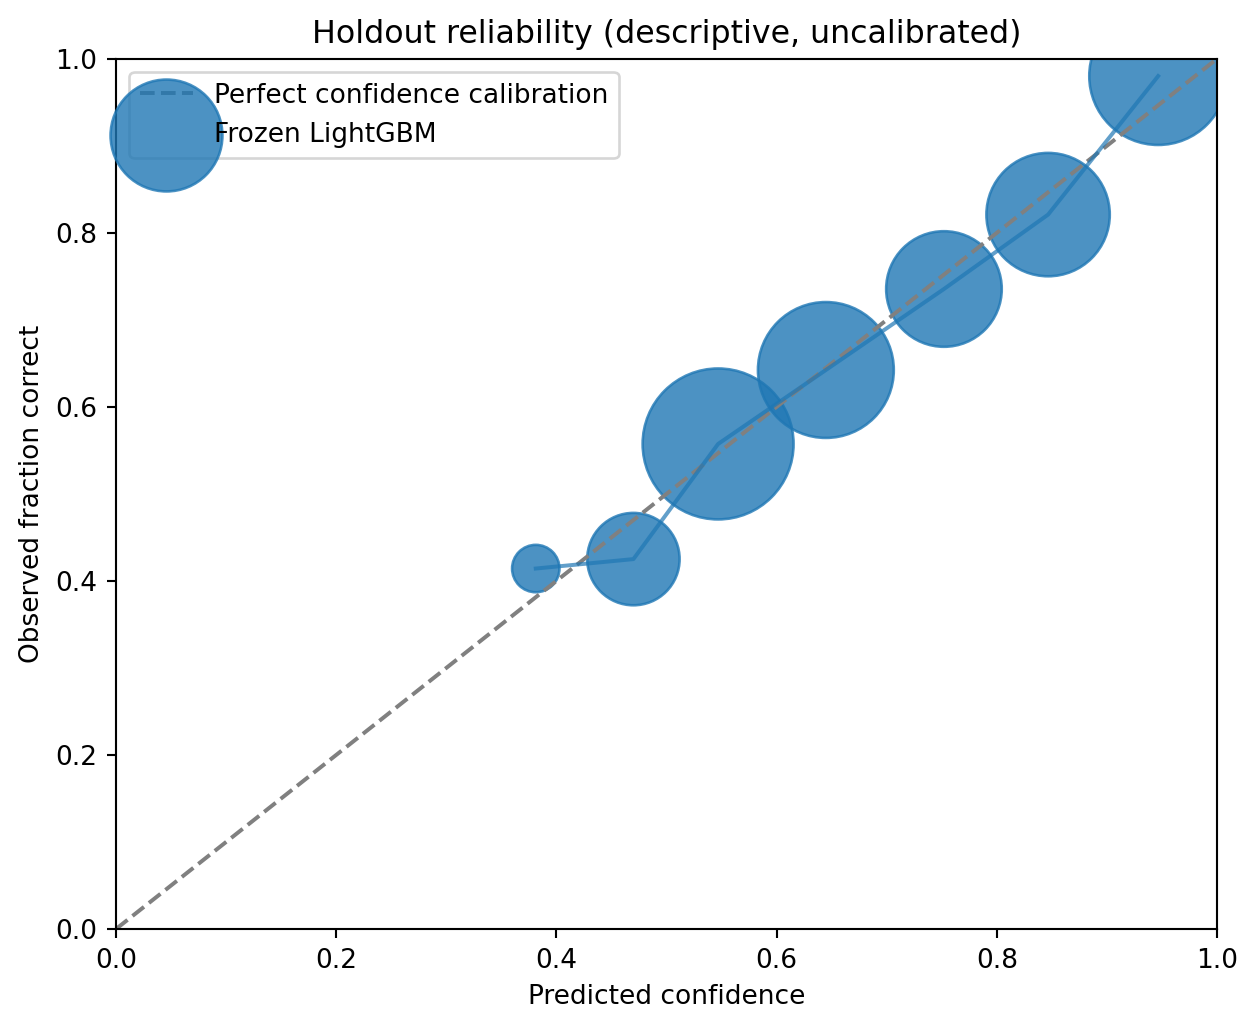

DEVELOPMENT_country_transfer.png


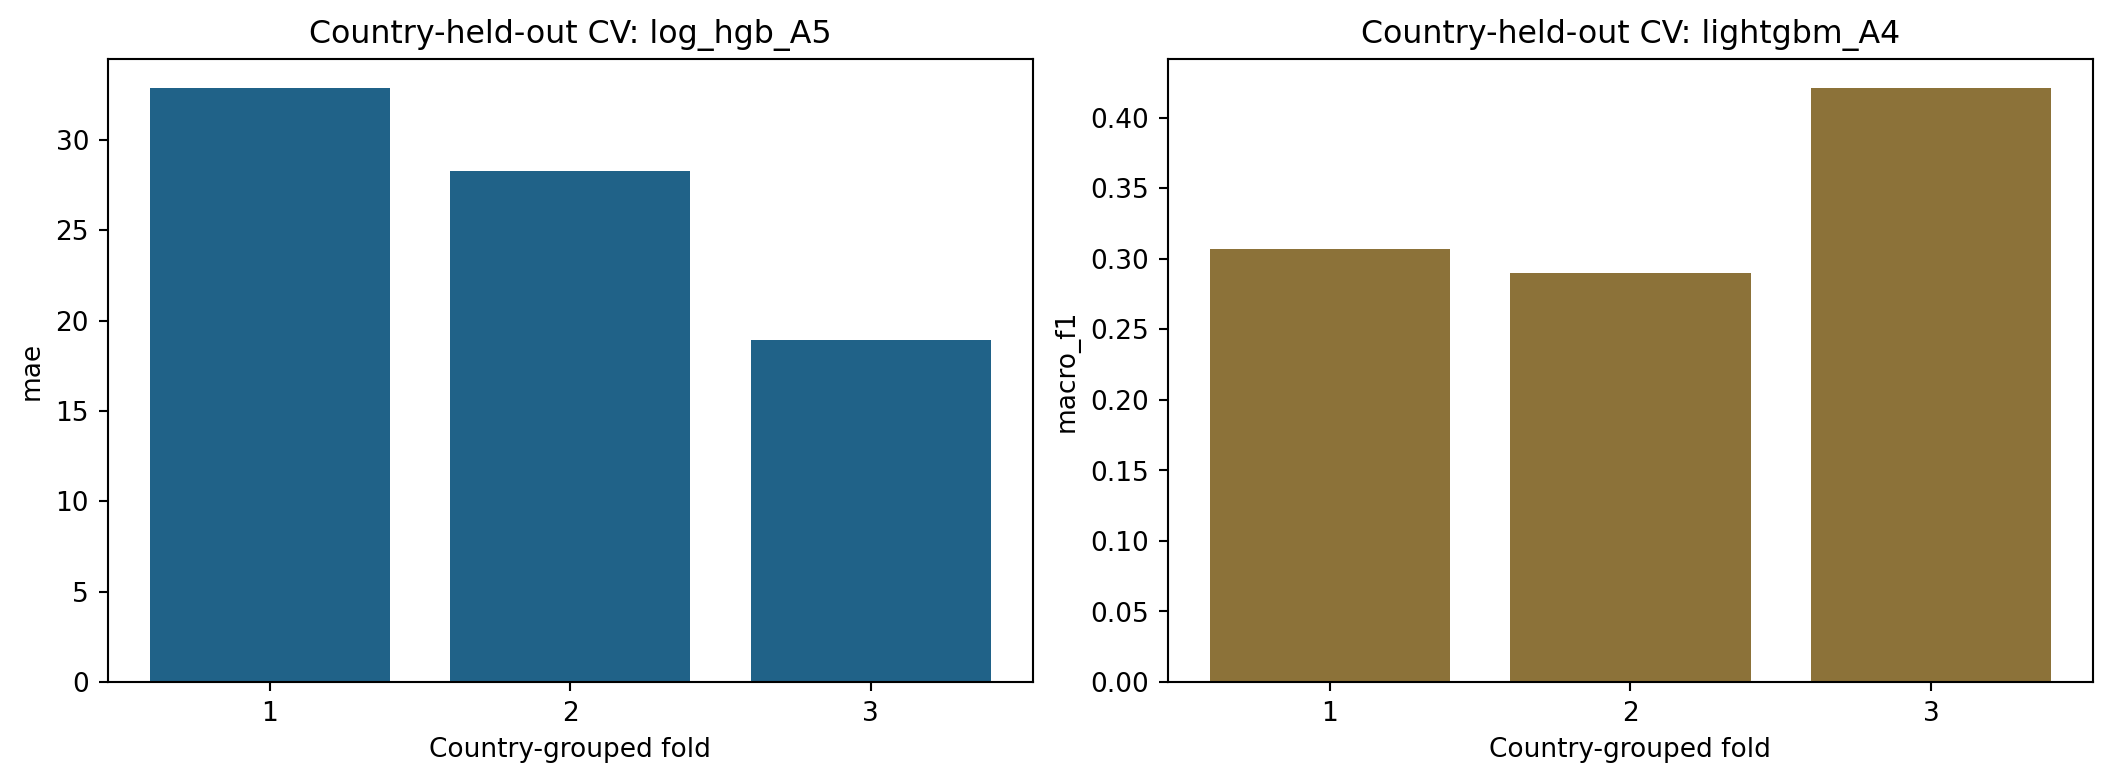

DEVELOPMENT_seven_stackers.png


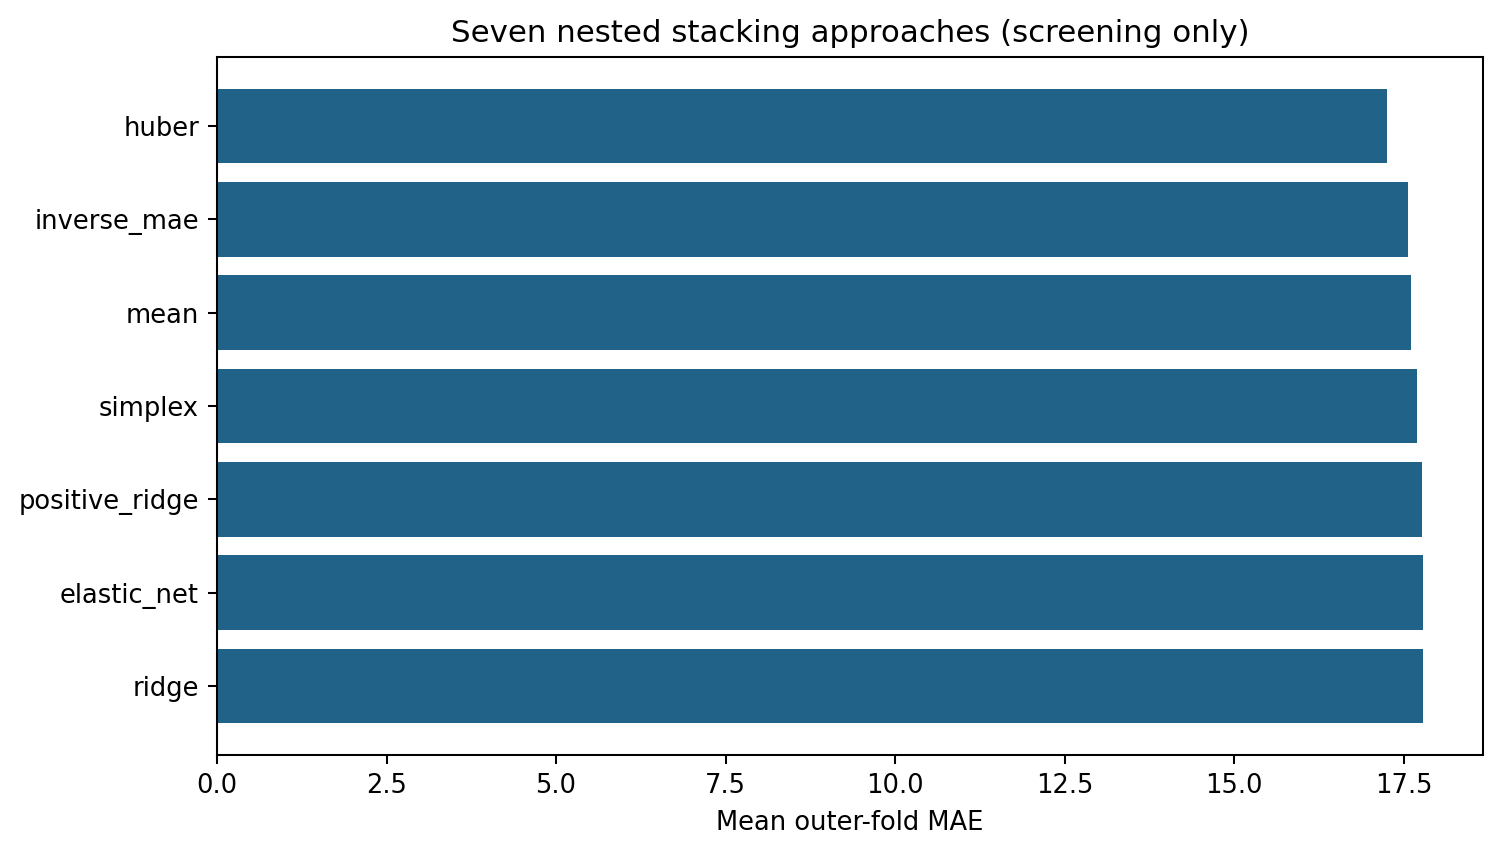

In [4]:
for fname in [
    "FINAL_fixed_models.png",
    "FINAL_confusion_matrices.png",
    "FINAL_per_category_recall.png",
    "FINAL_calibration.png",
    "DEVELOPMENT_country_transfer.png",
    "DEVELOPMENT_seven_stackers.png",
]:
    figure = base / "figures" / fname
    assert figure.is_file(), f"Archived figure missing: {fname}"
    print(fname)
    display(Image(filename=str(figure)))

## Important scientific limitations

- The same cross-sectional dataset was inspected during earlier analyses; the frozen 4,707-row holdout is **not independent external data**.
- No station/time sequences are available for genuine future-time forecasting.
- Exact-pattern grouping avoids exact predictor-tuple overlap, but country and sampling dependencies remain.
- The two rarest holdout categories contain **50 Very Unhealthy** and **29 Hazardous** records; macro-F1, recall and uncertainty matter.
- **Do not delete the receipt** or tune/choose models based on these final scores. Follow the CLI documentation for development-only reproducibility.